# CSCN8000 — Assignment 1
**Name:** Zeynep Ozdemir, 9045142

**Topic:** Parkinson’s Disease Classification


### Importing Libraries

This section imports the necessary Python libraries for data analysis, preprocessing, and visualization.

Machine learning algorithms such as KNN, Random Forest, SVM, and Decision Tree are imported for classification tasks.

Evaluation metrics are included to measure and compare model performance.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay)


# Question 1 — Data preprocessing 

In [10]:
# Skip the first header row and use the second row
df = pd.read_csv('../data/pd_speech_features.csv', header=1)

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

print("Dataset Shape:", df.shape)
print(df.head())

print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nClass Distribution:")
print(df['class'].value_counts())

print("\nUnique Patients:")
print(df['id'].nunique())

Dataset Shape: (756, 755)
   id  gender      PPE      DFA     RPDE  numPulses  numPeriodsPulses  \
0   0       1  0.85247  0.71826  0.57227        240               239   
1   0       1  0.76686  0.69481  0.53966        234               233   
2   0       1  0.85083  0.67604  0.58982        232               231   
3   1       0  0.41121  0.79672  0.59257        178               177   
4   1       0  0.32790  0.79782  0.53028        236               235   

   meanPeriodPulses  stdDevPeriodPulses  locPctJitter  ...  \
0          0.008064            0.000087       0.00218  ...   
1          0.008258            0.000073       0.00195  ...   
2          0.008340            0.000060       0.00176  ...   
3          0.010858            0.000183       0.00419  ...   
4          0.008162            0.002669       0.00535  ...   

   tqwt_kurtosisValue_dec_28  tqwt_kurtosisValue_dec_29  \
0                     1.5620                     2.6445   
1                     1.5589                

## 1.2 Separate features, target and patient ID

Feature matrix: (755, 753)
count
3    251
2      1
Name: count, dtype: int64


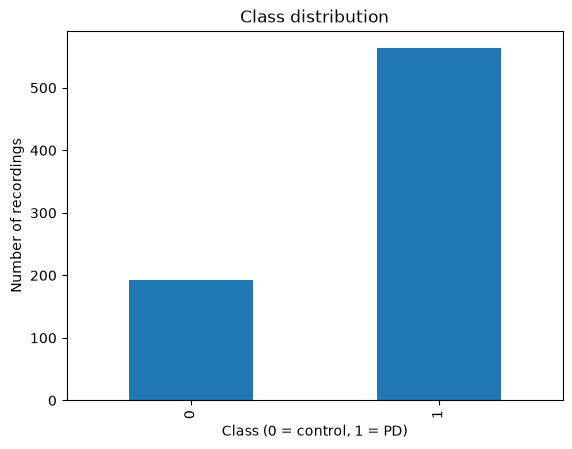

In [11]:
df = df.drop_duplicates().reset_index(drop=True)
y = df['class'].astype(int)
groups = df['id']
X = df.drop(columns=['id', 'class'])
X = X.apply(pd.to_numeric, errors='raise')
print('Feature matrix:', X.shape)
print(groups.value_counts().value_counts())
y.value_counts().sort_index().plot(kind='bar')
plt.title('Class distribution')
plt.xlabel('Class (0 = control, 1 = PD)')
plt.ylabel('Number of recordings')
plt.show()


## 1.3 Plan standardization

# Question 2 — 80% training data 

In [12]:
patients = df[['id', 'class']].drop_duplicates()
assert patients['id'].is_unique
train_ids, test_ids = train_test_split(
    patients['id'], test_size=0.20, random_state=42,
    stratify=patients['class'])
train_mask = groups.isin(train_ids)
test_mask = groups.isin(test_ids)
X_train, X_test = X.loc[train_mask], X.loc[test_mask]
y_train, y_test = y.loc[train_mask], y.loc[test_mask]
assert not set(train_ids).intersection(test_ids)
print('Training:', X_train.shape)
print('Testing:', X_test.shape)
print('Training %:', 100 * len(X_train) / len(X))
print('Test classes:', y_test.value_counts())


Training: (602, 753)
Testing: (153, 753)
Training %: 79.73509933774834
Test classes: class
1    114
0     39
Name: count, dtype: int64


# Question 3 — Model training 

In [13]:
models = {
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, random_state=42),
    'SVM': SVC(kernel='rbf', C=1),
    'Decision Tree': DecisionTreeClassifier(random_state=42)
}
trained = {}
for name, model in models.items():
    pipe = make_pipeline(SimpleImputer(strategy='median'),
                         StandardScaler(), model)
    pipe.fit(X_train, y_train)
    trained[name] = pipe
    print(name, 'trained successfully')


KNN trained successfully
Random Forest trained successfully
SVM trained successfully
Decision Tree trained successfully


# Question 4 — Test predictions 

In [14]:
predictions = pd.DataFrame({
    'Patient_ID': groups.loc[X_test.index],
    'Actual_Class': y_test
})
for name, model in trained.items():
    predictions[name] = model.predict(X_test)
print(predictions.head(10))


    Patient_ID  Actual_Class  KNN  Random Forest  SVM  Decision Tree
3            1             1    1              1    1              1
4            1             1    1              1    1              1
5            1             1    1              1    1              0
9            3             1    1              1    1              1
10           3             1    1              1    1              1
11           3             1    0              1    1              1
24           8             1    1              1    1              1
25           8             1    0              1    1              1
26           8             1    0              1    1              1
45          15             1    1              1    1              1


# Question 5 — Predictive system

In [15]:
def predict_patient(sample):
    if set(sample.columns) != set(X_train.columns):
        raise ValueError('Feature columns do not match training data')
    sample = sample[X_train.columns]
    results = {}
    for name, model in trained.items():
        label = int(model.predict(sample)[0])
        results[name] = 'Parkinson’s disease' if label == 1 else 'Control'
    return results

# Demonstration: a held-out recording, unseen during training
new_sample = X_test.iloc[[0]].copy()
print('Predictions:', predict_patient(new_sample))
print('Actual class:', y_test.iloc[0])


Predictions: {'KNN': 'Parkinson’s disease', 'Random Forest': 'Parkinson’s disease', 'SVM': 'Parkinson’s disease', 'Decision Tree': 'Parkinson’s disease'}
Actual class: 1


# Question 6 — Evaluate the models

KNN Accuracy: 0.7516
              precision    recall  f1-score   support

     Control       0.52      0.36      0.42        39
          PD       0.80      0.89      0.84       114

    accuracy                           0.75       153
   macro avg       0.66      0.62      0.63       153
weighted avg       0.73      0.75      0.74       153



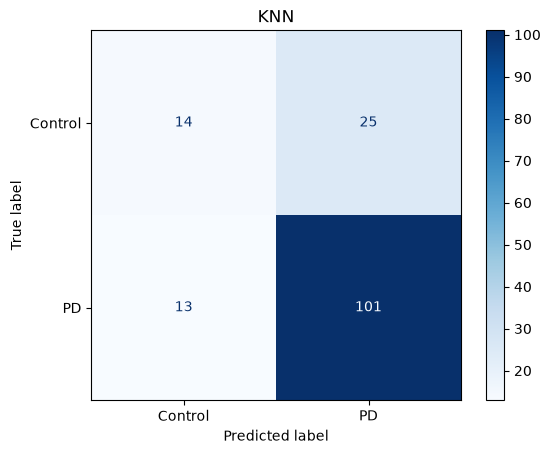

Random Forest Accuracy: 0.8039
              precision    recall  f1-score   support

     Control       0.71      0.38      0.50        39
          PD       0.82      0.95      0.88       114

    accuracy                           0.80       153
   macro avg       0.77      0.67      0.69       153
weighted avg       0.79      0.80      0.78       153



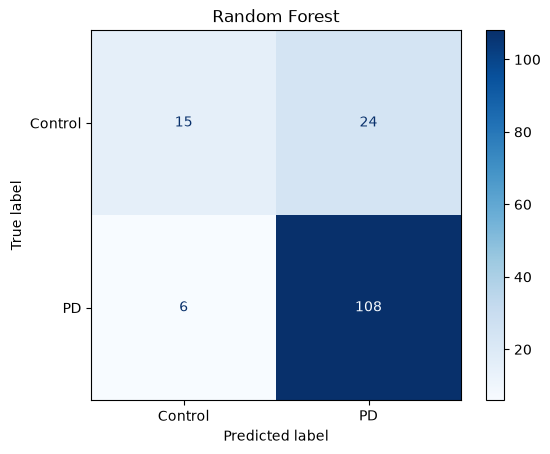

SVM Accuracy: 0.8039
              precision    recall  f1-score   support

     Control       0.74      0.36      0.48        39
          PD       0.81      0.96      0.88       114

    accuracy                           0.80       153
   macro avg       0.78      0.66      0.68       153
weighted avg       0.79      0.80      0.78       153



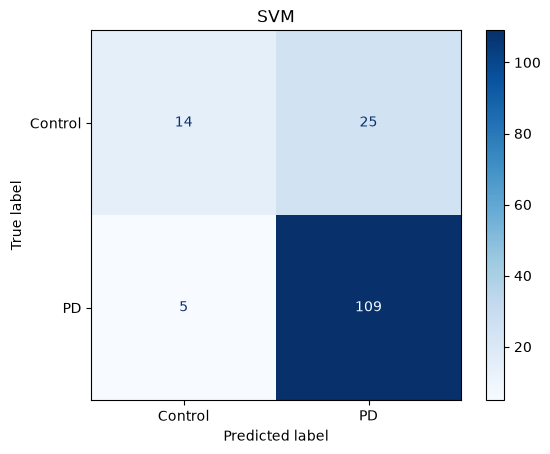

Decision Tree Accuracy: 0.732
              precision    recall  f1-score   support

     Control       0.47      0.41      0.44        39
          PD       0.81      0.84      0.82       114

    accuracy                           0.73       153
   macro avg       0.64      0.63      0.63       153
weighted avg       0.72      0.73      0.73       153



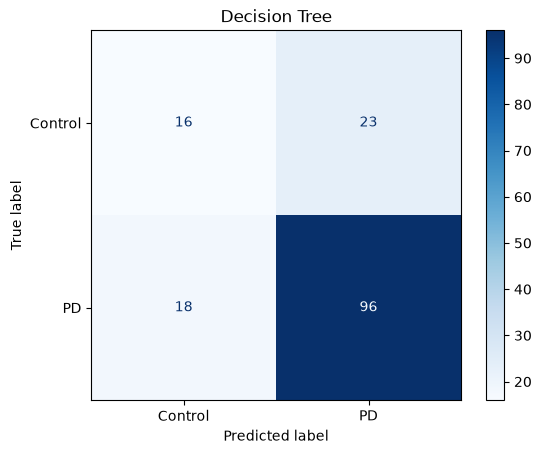

        Model  Accuracy  Precision_PD  Recall_PD  F1_PD  TN  FP  FN  TP
Random Forest    0.8039        0.8182     0.9474 0.8780  15  24   6 108
          SVM    0.8039        0.8134     0.9561 0.8790  14  25   5 109
          KNN    0.7516        0.8016     0.8860 0.8417  14  25  13 101
Decision Tree    0.7320        0.8067     0.8421 0.8240  16  23  18  96
Best model(s): ['Random Forest', 'SVM']
Best accuracy: 0.803921568627451


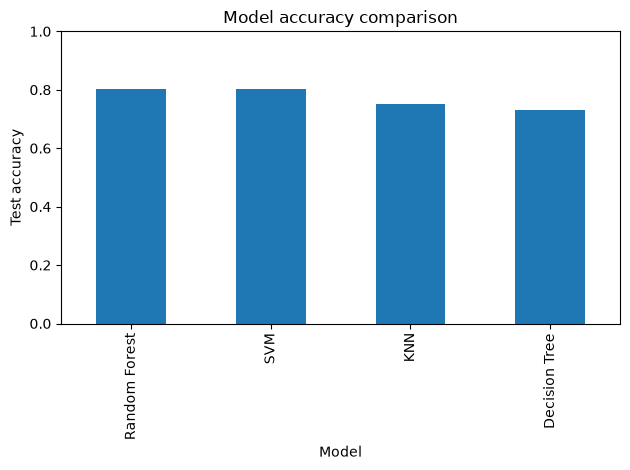

In [16]:
rows = []
for name in trained:
    pred = predictions[name]
    acc = accuracy_score(y_test, pred)
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    report = classification_report(y_test, pred,
        labels=[0, 1], output_dict=True, zero_division=0)
    tn, fp, fn, tp = cm.ravel()
    rows.append({'Model': name, 'Accuracy': acc,
        'Precision_PD': report['1']['precision'],
        'Recall_PD': report['1']['recall'],
        'F1_PD': report['1']['f1-score'],
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp})
    print(name, 'Accuracy:', round(acc, 4))
    print(classification_report(y_test, pred, labels=[0, 1],
        target_names=['Control', 'PD'], zero_division=0))
    ConfusionMatrixDisplay(cm,
        display_labels=['Control', 'PD']).plot(cmap='Blues')
    plt.title(name)
    plt.show()

summary = pd.DataFrame(rows).sort_values(
    'Accuracy', ascending=False).reset_index(drop=True)
print(summary.round(4).to_string(index=False))
best = summary[summary['Accuracy'] == summary['Accuracy'].max()]
print('Best model(s):', best['Model'].tolist())
print('Best accuracy:', best['Accuracy'].iloc[0])
summary.set_index('Model')['Accuracy'].plot(kind='bar', ylim=(0, 1))
plt.ylabel('Test accuracy')
plt.title('Model accuracy comparison')
plt.tight_layout()
plt.show()


# Question 6 — Write your findings

# Question 7 — Save all predictions 

In [17]:
predictions.to_csv('test_predictions.csv', index=False)
check = pd.read_csv('test_predictions.csv')
print(check.shape)
print(check.head())
assert len(check) == len(X_test)


(153, 6)
   Patient_ID  Actual_Class  KNN  Random Forest  SVM  Decision Tree
0           1             1    1              1    1              1
1           1             1    1              1    1              1
2           1             1    1              1    1              0
3           3             1    1              1    1              1
4           3             1    1              1    1              1
